In [26]:
import geopandas as gpd
import pandas as pd
from sklearn import linear_model
import numpy as np
import matplotlib.pyplot as plt

In [3]:
gdf_DZ22_results = gpd.read_file("Prepared data for regression/Kintore-Tealing-DZ22-X_Y.geojson")
gdf_DZ22_results = gdf_DZ22_results.set_index("outputAreaCode")
gdf_DZ22_results.sample(10)

,pop_total,area_sqkm,density_pop/sqkm,distance_to_route,DZ22_Name,IZ22_Name,LA_Name,UR22_8FOLD_MIN,p_children,mean_adult_age,...,p_L1_to_L6,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute,cumulativeActivity,modelled_per_100,empirical,empirical_per_100,geometry
outputAreaCode,,,,,,,,,,,,,,,,,,,,,
S01013896,905,0.272671,3319.019268,7029.265984,Inverurie North - 01,Inverurie North,Aberdeenshire,2,0.156425,56.725828,...,0.340180,0.489433,0.013348,0.722838,0.592000,0.254907,0.028167,0.0,0.0,"POLYGON ((376865.29 821293.302, 376860.075 821..."
S01015466,610,0.108699,5611.841213,5348.695734,Whitfield - 08,Whitfield,Dundee City,1,0.294314,46.502370,...,0.169851,0.324013,0.013158,0.164763,0.484000,0.198646,0.032565,0.0,0.0,"POLYGON ((343296.939 733919.235, 343303.333 73..."
S01013943,574,0.348437,1647.358132,7139.348599,Westhill Central - 02,Westhill Central,Aberdeenshire,2,0.186715,55.492274,...,0.455852,0.416667,0.019504,0.881326,0.527675,0.157066,0.027363,0.0,0.0,"POLYGON ((384096.543 806806.315, 384138.297 80..."
S01015421,591,0.164249,3598.201705,7292.728155,Douglas West - 03,Douglas West,Dundee City,1,0.183074,51.923890,...,0.181452,0.455760,0.013356,0.522807,0.401575,0.132813,0.022473,0.0,0.0,"POLYGON ((343972 732000, 343973.752 731961.57,..."
S01015398,1096,0.123365,8884.187258,5923.275922,Clepington - 03,Clepington,Dundee City,1,0.184906,46.347222,...,0.229630,0.474406,0.129799,0.368710,0.389247,0.349665,0.031904,0.0,0.0,"POLYGON ((340582 731836, 340585 731862, 340586..."
S01013894,714,0.212788,3355.446381,3474.413756,Kemnay - 04,Kemnay,Aberdeenshire,3,0.256516,51.409594,...,0.324653,0.343220,0.007062,0.639665,0.525862,1.736640,0.243227,0.0,0.0,"POLYGON ((373610 816034, 373557.696 816032.769..."
S01013832,782,2.606698,299.996404,5369.036458,Stonehaven North - 05,Stonehaven North,Aberdeenshire,2,0.324561,46.649351,...,0.550265,0.350765,0.010204,0.846939,0.581731,0.285368,0.036492,0.0,0.0,"POLYGON ((386489.107 786908.609, 386495.161 78..."
S01015517,591,0.147378,4010.109264,6591.808246,Balgay - 04,Balgay,Dundee City,1,0.175439,57.078723,...,0.395257,0.546552,0.031034,0.881072,0.568182,0.256712,0.043437,0.0,0.0,"POLYGON ((337549.131 731124.253, 337543.182 73..."
S01013899,637,0.147985,4304.477024,7812.381450,Inverurie North - 04,Inverurie North,Aberdeenshire,2,0.155592,54.669866,...,0.332714,0.426128,0.004666,0.859155,0.593060,0.135181,0.021221,0.0,0.0,"POLYGON ((376674.662 822330.032, 376690 822313..."


In [10]:
gdf_DZ22_results.iloc[:,[2,3,7,8,9,10,11,12,13,14,15,16,17,18,21]]

,density_pop/sqkm,distance_to_route,UR22_8FOLD_MIN,p_children,mean_adult_age,p_level_4,p_green_heating,p_married,p_born_in_UK,p_L1_to_L6,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute,empirical
outputAreaCode,,,,,,,,,,,,,,,
S01013482,220.538710,3504.062956,1,0.184346,51.323232,0.426829,0.003432,0.416667,0.876939,0.402628,0.400419,0.014675,0.717119,0.509514,0.0
S01013483,2082.474261,5579.078287,1,0.169960,55.484127,0.346645,0.000000,0.456579,0.886093,0.366559,0.442408,0.036649,0.740741,0.535826,0.0
S01013484,2119.672902,5758.693477,1,0.205556,47.086247,0.428571,0.000000,0.322993,0.896296,0.410200,0.371115,0.029250,0.751381,0.593443,0.0
S01013485,5828.313590,6405.758335,1,0.229706,51.515695,0.339326,0.001976,0.410619,0.884477,0.345494,0.400362,0.052536,0.741071,0.541176,0.0
S01013486,3431.873321,6590.597866,1,0.204800,55.655936,0.328155,0.000000,0.447504,0.909968,0.330116,0.423263,0.022617,0.676370,0.569343,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
S01019261,353.537336,8480.227004,6,0.194940,58.650647,0.437710,0.000000,0.537037,0.953456,0.494058,0.565280,0.012912,0.879944,0.602740,0.0
S01019262,650.538440,8790.299414,6,0.170752,54.712315,0.460452,0.018466,0.539964,0.939222,0.469388,0.513799,0.015422,0.796099,0.542190,0.0
S01019263,1478.969028,8163.271403,1,0.207216,51.330299,0.410824,0.002255,0.422405,0.899590,0.420596,0.475460,0.028630,0.738509,0.504854,0.0


In [13]:
chosen_columns = ["density_pop/sqkm", "distance_to_route", "UR22_8FOLD_MIN", "p_children", "mean_adult_age", "p_level_4", "p_green_heating", "p_married", "p_born_in_UK", "p_L1_to_L6", "p_religion", "p_nonchristian_religion", "p_owned","p_car_drive_commute"]

In [14]:
df_normalised = pd.DataFrame()
for col in chosen_columns:
    df_normalised[col] = gdf_DZ22_results[col]/gdf_DZ22_results[col].mean()
X = np.array(df_normalised)
X

array([[4.49525236e-03, 6.27131672e-01, 3.97930386e-01, ...,
        4.24838294e-01, 1.07669759e+00, 1.01642624e+00],
       [4.24471845e-02, 9.98502806e-01, 3.97930386e-01, ...,
        1.06098359e+00, 1.11216377e+00, 1.06891551e+00],
       [4.32054064e-02, 1.03064902e+00, 3.97930386e-01, ...,
        8.46791816e-01, 1.12813961e+00, 1.18385551e+00],
       ...,
       [3.01459050e-02, 1.46100287e+00, 3.97930386e-01, ...,
        8.28825629e-01, 1.10881251e+00, 1.00713128e+00],
       [8.01808010e-02, 1.70559131e+00, 2.38758231e+00, ...,
        3.62282875e-01, 1.01586978e+00, 1.12985184e+00],
       [2.17029806e-03, 1.24962282e+00, 2.38758231e+00, ...,
        1.24070122e-01, 1.12270443e+00, 1.16898285e+00]], shape=(423, 14))

In [28]:
Y = np.array(gdf_DZ22_results["empirical_per_100"].map(lambda x:np.sign(x)))
gdf_DZ22_results["Y"] = Y
Y

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 1., 1., 1., 1., 0., 0., 1., 0., 1., 1., 0., 1., 1.,
       1., 1., 1., 0., 0., 1., 0., 0., 1., 0., 1., 0., 1., 1., 0., 0., 1.,
       0., 0., 1., 1., 0., 0., 0., 1., 0., 0., 1., 0., 0., 0., 1., 1., 1.,
       1., 0., 0., 0., 0., 1., 0., 0., 1., 1., 1., 0., 1., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 1., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 1., 0., 1., 1.,
       1., 1., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.,
       1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 1., 1.

In [15]:
logr = linear_model.LogisticRegression()
logr.fit(X,Y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [16]:
logr

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [21]:
df_normalised.columns

Index(['density_pop/sqkm', 'distance_to_route', 'UR22_8FOLD_MIN', 'p_children',
       'mean_adult_age', 'p_level_4', 'p_green_heating', 'p_married',
       'p_born_in_UK', 'p_L1_to_L6', 'p_religion', 'p_nonchristian_religion',
       'p_owned', 'p_car_drive_commute'],
      dtype='object')

In [52]:
df_normalised["predicted"] = logr.predict(X)


In [59]:
df_normalised["predict_proba"] = logr.predict_proba(X)[:,1]

In [27]:
df_normalised

,density_pop/sqkm,distance_to_route,UR22_8FOLD_MIN,p_children,mean_adult_age,p_level_4,p_green_heating,p_married,p_born_in_UK,p_L1_to_L6,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute,predicted
outputAreaCode,,,,,,,,,,,,,,,
S01013482,0.004495,0.627132,0.397930,0.850620,1.005808,1.269855,0.521652,0.974301,0.969634,1.171003,0.911323,0.424838,1.076698,1.016426,0.0
S01013483,0.042447,0.998503,0.397930,0.784241,1.087351,1.031301,0.000000,1.067628,0.979755,1.066100,1.006886,1.060984,1.112164,1.068916,0.0
S01013484,0.043205,1.030649,0.397930,0.948486,0.922773,1.275038,0.000000,0.755261,0.991038,1.193023,0.844629,0.846792,1.128140,1.183856,0.0
S01013485,0.118799,1.146456,0.397930,1.059924,1.009579,1.009525,0.300345,0.960160,0.977968,1.004832,0.911193,1.520908,1.112660,1.079590,0.0
S01013486,0.069952,1.179537,0.397930,0.944999,1.090718,0.976292,0.000000,1.046409,1.006154,0.960108,0.963314,0.654759,1.015516,1.135779,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
S01019261,0.007206,1.517729,2.387582,0.899505,1.149407,1.302228,0.000000,1.255765,1.054239,1.436916,1.286532,0.373812,1.321166,1.202402,0.0
S01019262,0.013260,1.573224,2.387582,0.787892,1.072225,1.369886,2.806350,1.262611,1.038501,1.365166,1.169365,0.446464,1.195280,1.081613,0.0
S01019263,0.030146,1.461003,0.397930,0.956150,1.005946,1.222239,0.342671,0.987719,0.994680,1.223259,1.082110,0.828826,1.108813,1.007131,0.0


In [60]:
gdf_DZ22_results["predicted"] = df_normalised["predicted"]
gdf_DZ22_results["predicted_proba"] = df_normalised["predict_proba"]

In [34]:
gdf_DZ22_results["dummy"] = 1.0

In [35]:
pd.pivot_table(gdf_DZ22_results, index = "Y", columns = "predicted", values = ["dummy"], aggfunc = "count")
# May want to weight the OAs with representations higher, to try and reduce the false negatives.

dummy    
predicted   0.0 1.0
Y                  
0.0         363   9
1.0          30  21

In [54]:
logr.score(X,Y) # This is just the proportion of samples classified correctly.
# But what about if we look at unseen data???

0.9078014184397163

In [31]:
df_normalised["predicted"].iloc[0]

np.float64(0.0)

In [74]:
coeff_dict = dict(zip(list(chosen_columns), logr.coef_[0].tolist()))
pd.Series(coeff_dict)

density_pop/sqkm          -0.200942
distance_to_route         -1.324374
UR22_8FOLD_MIN             0.872893
p_children                -0.200221
mean_adult_age             0.283532
p_level_4                  0.678081
p_green_heating           -0.061548
p_married                  0.395966
p_born_in_UK              -0.079636
p_L1_to_L6                 0.290809
p_religion                -0.582866
p_nonchristian_religion   -1.135905
p_owned                    0.132319
p_car_drive_commute       -0.842386
dtype: float64

Text(0, 0.5, 'empirical observations')

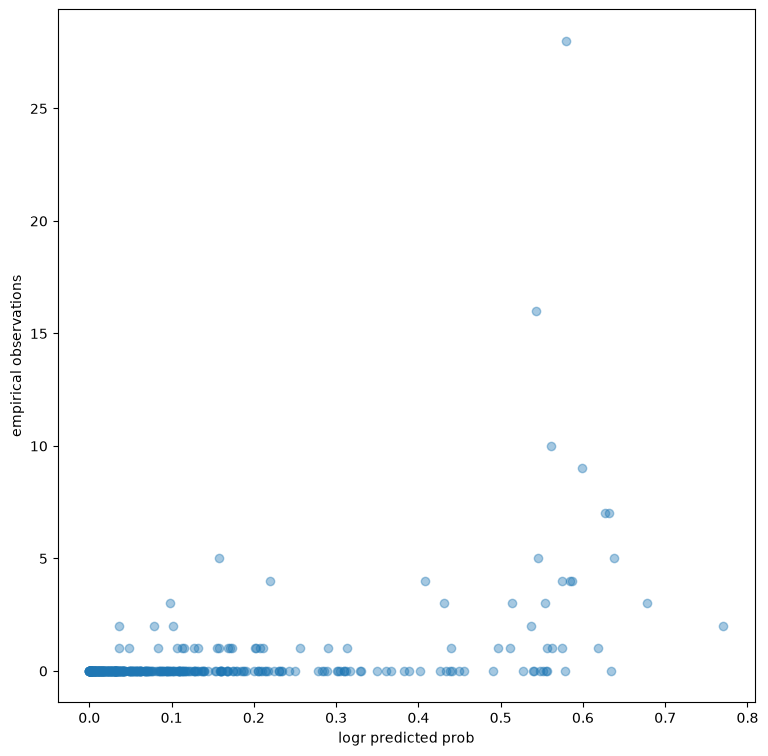

In [65]:
# I wonder if it would be better to separate distance in the statistic model.
fig, ax = plt.subplots(figsize = (9,9))
plt.scatter(gdf_DZ22_results["predicted_proba"], gdf_DZ22_results["empirical"], alpha = 0.4)
ax.set_xlabel("logr predicted prob")
ax.set_ylabel("empirical observations")

In [69]:
gdf_DZ22_results.loc[:,["empirical", "predicted_proba"]].corr(method = 'pearson')
# This correlation is less good than the ABM, although we are not quite comparing apples with apples.

,empirical,predicted_proba
empirical,1.0000,0.4476
predicted_proba,0.4476,1.0000


In [70]:
gdf_DZ22_results.loc[:,["empirical", "predicted_proba"]].corr(method = 'spearman')

,empirical,predicted_proba
empirical,1.000000,0.435288
predicted_proba,0.435288,1.000000
